# Mini-Project 3 — Lake Victoria Fish Stock & Export Risk Model (Jinja cooperative)

**Questions.** (a) Is the harvesting rate sustainable? (b) How risky is revenue?

**Assumptions.** One time step = one week. Stock is in tonnes, harvest is converted to kg (×1,000), price is in UGX/kg, revenue in UGX. The parameters r = 0.4 per week, K = 10,000 t and N₀ = 4,000 t come from the brief and are illustrative. A real Nile-perch growth rate is far slower than 40% a week, so the *dynamics* here are compressed in time. The price process is a seeded, bounded random walk (UGX 9,000–16,000/kg, weekly step SD UGX 400).

Classes live in `src/fisheries.py`: `FishStock`, `PriceModel`, `RiskAssessor`.

In [1]:
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.fisheries import KG_PER_TONNE, FishStock, PriceModel, RiskAssessor, fibonacci, msy, revenue_stats

SEED = 2026
WEEKS = 52
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Baseline: Fibonacci "stock"

In [2]:
fib = fibonacci(15)
print("15 Fibonacci 'stock' values:", fib.tolist())
print("Growth factor of the last step:", round(fib[-1] / fib[-2], 4))

15 Fibonacci 'stock' values: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Growth factor of the last step: 1.618


Fibonacci growth is unbounded and geometric: each step multiplies the stock by about 1.618 forever, so after 50 steps a 1-tonne stock would exceed 10¹⁰ tonnes, more fish than Lake Victoria could physically hold. Real populations are limited by food, oxygen and space, so per-capita growth **slows as density rises** and the stock levels off near a carrying capacity. The recurrence also has no mortality, no harvesting term and no parameter that can be estimated from catch data. It cannot answer the cooperative's actual question: what harvest the stock can sustain.

## 2. Logistic stock with harvesting: `FishStock`
N(t+1) = N(t) + r·N(t)·(1 − N(t)/K) − h·N(t). Setting N(t+1) = N(t) gives the steady state **N\* = K(1 − h/r)**, with long-run catch h·N\* = rK·(h/r)(1 − h/r). That catch is largest at h = r/2, where it equals **MSY = rK/4**.

In [3]:
fs = FishStock(r=0.4, k=10_000, n0=4_000, h=0.10)
stock, harvest = fs.simulate(WEEKS)
print(fs)
print(f"Week 1 by hand: 4000 + 0.4·4000·(1 − 0.4) − 0.1·4000 = {4000 + 0.4*4000*0.6 - 400:.0f}  | model: {stock[1]:.0f}")
print(f"Final stock after {WEEKS} weeks: {stock[-1]:,.1f} t  | theoretical N* = {fs.equilibrium:,.0f} t")
print(f"MSY = rK/4 = {msy(fs.r, fs.k):,.0f} t/week at h = r/2 = {fs.r / 2}")

FishStock(r=0.4, K=10,000 t, N0=4,000 t, h=0.1)
Week 1 by hand: 4000 + 0.4·4000·(1 − 0.4) − 0.1·4000 = 4560  | model: 4560
Final stock after 52 weeks: 7,500.0 t  | theoretical N* = 7,500 t
MSY = rK/4 = 1,000 t/week at h = r/2 = 0.2


## 3. Price: `PriceModel` (bounded random walk)

In [4]:
pm = PriceModel(start=12_000, low=9_000, high=16_000, step_sd=400, seed=SEED)
price = pm.simulate(WEEKS)
revenue = harvest * KG_PER_TONNE * price
print(pm)
print(f"Price range over the year: UGX {price.min():,.0f}–{price.max():,.0f}/kg")
print(f"Week 1 revenue: {harvest[0]:.0f} t × 1,000 kg × UGX {price[0]:,.0f} = UGX {revenue[0]:,.0f}")

PriceModel(start=12,000, bounds=[9,000, 16,000], sd=400)
Price range over the year: UGX 11,020–16,000/kg
Week 1 revenue: 400 t × 1,000 kg × UGX 12,000 = UGX 4,800,000,000


## 4. Revenue statistics and why "variance > 50,000" is meaningless

In [5]:
rs = revenue_stats(revenue)
display(pd.Series(rs, name="weekly revenue (h = 0.10)").to_frame()
        .assign(units=["UGX", "UGX", "UGX²", "UGX", "dimensionless"]))
print(f"Variance = {rs['variance']:.3e} UGX²  vs old threshold 50,000 → ratio {rs['variance'] / 50_000:.1e}")
print(f"Same revenue measured in millions of UGX: variance = {revenue_stats(revenue / 1e6)['variance']:,.1f} (M UGX)²")
print(f"CV in UGX: {rs['cv']:.4f}  | CV in M UGX: {revenue_stats(revenue / 1e6)['cv']:.4f}")

,weekly revenue (h = 0.10),units
mean,"8,862,347,015.848",UGX
median,"8,893,470,327.890",UGX
variance,"1,850,918,709,937,862,144.000",UGX²
stdev,"1,360,484,733.445",UGX
cv,0.154,dimensionless


Variance = 1.851e+18 UGX²  vs old threshold 50,000 → ratio 3.7e+13
Same revenue measured in millions of UGX: variance = 1,850,918.7 (M UGX)²
CV in UGX: 0.1535  | CV in M UGX: 0.1535


Variance is measured in **squared currency units** (UGX²), so its size depends entirely on the unit and the scale of the business. The same revenue series has a variance of about 1.4×10¹⁸ UGX² measured in shillings and about 1.4×10⁶ measured in millions of shillings. A fixed threshold of 50,000 is exceeded ~10¹³-fold in one unit and could pass in another. It would flag *every* cooperative bigger than a market stall as "risky" and says nothing about whether swings are large *relative to income*. The **coefficient of variation** (SD ÷ mean) is dimensionless and identical in any unit, so it is the right basis for a risk rule.

## 5. `RiskAssessor`: CV-based rule and Monte Carlo Value-at-Risk
**Rule:** CV < 0.10 → *Low*; 0.10 ≤ CV < 0.25 → *Moderate*; CV ≥ 0.25 → *High*. Justification: a cooperative carries mostly fixed weekly costs (crew wages, boat fuel, ice, licence fees). With CV < 10%, a typical week stays within ±10% of budget and cash buffers absorb it. Above 25%, one week in six is more than 25% short, which threatens payroll unless the cooperative holds reserves. These cut-offs are a judgement call, stated openly, and the class accepts different thresholds.

**VaR:** simulate 1,000 independent price paths for a fixed harvest plan, sum each into annual revenue, and take the 5th percentile. VaR₅% = expected annual revenue − 5th percentile, i.e. the shortfall below expectation that is exceeded only 1 year in 20.

In [6]:
ra = RiskAssessor(low=0.10, high=0.25)
annual = ra.monte_carlo(harvest, pm, n_paths=1000, seed=SEED)
var = ra.value_at_risk(annual, level=0.05)
print(f"Risk class (weekly revenue CV = {rs['cv']:.3f}): {ra.classify(rs['cv'])}")
print(f"Expected annual revenue: UGX {var['expected'] / 1e9:,.1f} bn")
print(f"5th percentile         : UGX {var['quantile'] / 1e9:,.1f} bn")
print(f"95% VaR (shortfall)    : UGX {var['VaR'] / 1e9:,.1f} bn  = {var['VaR'] / var['expected']:.1%} of expected revenue")

Risk class (weekly revenue CV = 0.154): Moderate
Expected annual revenue: UGX 450.7 bn
5th percentile         : UGX 375.9 bn
95% VaR (shortfall)    : UGX 74.7 bn  = 16.6% of expected revenue


## 6. Scenario analysis: h = 0.05, 0.10, 0.20, 0.30

In [7]:
rates = [0.05, 0.10, 0.20, 0.30]
rows, trajectories, mc_by_h = [], {}, {}
for h in rates:
    model = FishStock(h=h)
    st, hv = model.simulate(WEEKS)
    rev = hv * KG_PER_TONNE * price            # same price path for a like-for-like comparison
    stats_h = revenue_stats(rev)
    mc = ra.monte_carlo(hv, pm, n_paths=1000, seed=SEED)
    v = ra.value_at_risk(mc)
    trajectories[h], mc_by_h[h] = st, mc
    rows.append({"h": h, "final stock (t)": st[-1], "N* (t)": model.equilibrium,
                 "mean weekly catch (t)": hv.mean(), "long-run catch h·N* (t/wk)": model.sustainable_yield,
                 "catch / MSY": model.sustainable_yield / msy(0.4, 10_000),
                 "total revenue (bn UGX)": rev.sum() / 1e9, "weekly CV": stats_h["cv"],
                 "risk class": ra.classify(stats_h["cv"]), "VaR5% (% of mean)": v["VaR"] / v["expected"] * 100})
scen = pd.DataFrame(rows).set_index("h")
display(scen)
print(f"MSY = rK/4 = {msy(0.4, 10_000):,.0f} t/week, reached at h = r/2 = 0.20 with N* = K/2 = 5,000 t")

,final stock (t),N* (t),mean weekly catch (t),long-run catch h·N* (t/wk),catch / MSY,total revenue (bn UGX),weekly CV,risk class,VaR5% (% of mean)
h,,,,,,,,,
0.050,"8,750.000","8,750.000",417.589,437.500,0.438,267.886,0.166,Moderate,16.647
0.100,"7,500.000","7,500.000",718.510,750.000,0.750,460.842,0.154,Moderate,16.583
0.200,"4,999.988","5,000.000",978.302,"1,000.000",1.000,626.788,0.112,Moderate,16.310
0.300,"2,503.717","2,500.000",816.558,750.000,0.750,520.539,0.121,Moderate,15.511


MSY = rK/4 = 1,000 t/week, reached at h = r/2 = 0.20 with N* = K/2 = 5,000 t


* **h = 0.20 is the MSY rate**: the stock settles at K/2 = 5,000 t and yields exactly rK/4 = 1,000 t/week, and it earns the most revenue of the four.
* **h = 0.30 over-harvests.** Year-one revenue is still second-best, because it starts by mining a stock that is above its new equilibrium. The stock then falls to 2,500 t and the long-run catch drops to 750 t/week, the *same* as h = 0.10 but from a stock a third the size and far more exposed to a bad recruitment year. Its year-one revenue overstates what it can sustain.
* **h = 0.05 and 0.10 are conservative**: large standing stocks, safe, but they leave 56% and 25% of the sustainable yield uncaught.
* All four rates fall in the *Moderate* class because price risk is the same for all of them. The smaller CV differences come from how much the *catch* changes during the year as the stock moves from 4,000 t to its equilibrium; at h = 0.20 that move is smallest, hence the lowest CV. VaR as a share of revenue is about 15.5–16.6% for all rates: price risk scales with volume.

## 7. Charts

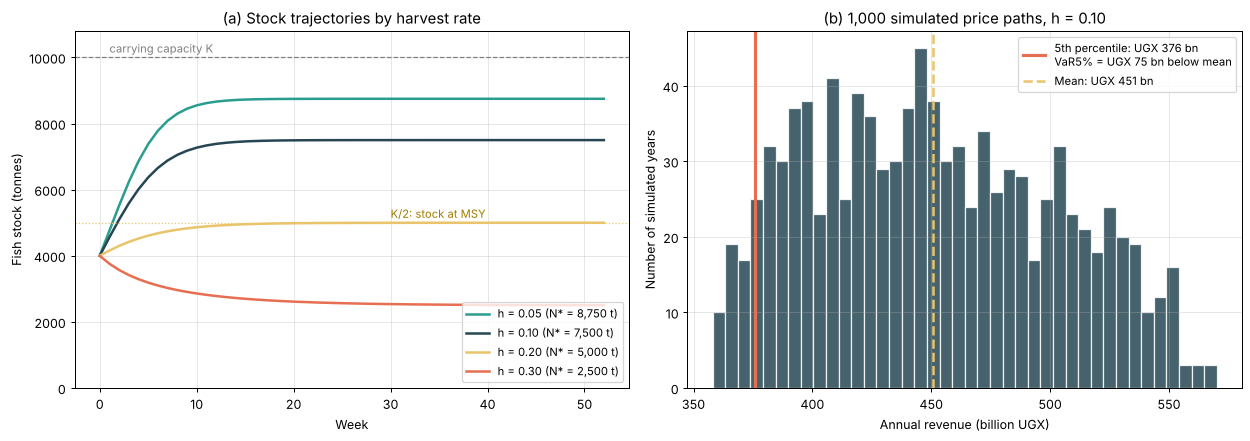

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {0.05: "#2a9d8f", 0.10: "#264653", 0.20: "#e9c46a", 0.30: "#e76f51"}
for h, st in trajectories.items():
    axes[0].plot(np.arange(WEEKS + 1), st, color=colors[h], lw=2, label=f"h = {h:.2f} (N* = {FishStock(h=h).equilibrium:,.0f} t)")
axes[0].axhline(10_000, color="grey", ls="--", lw=1)
axes[0].text(1, 10_150, "carrying capacity K", color="grey", fontsize=9)
axes[0].axhline(5_000, color="#e9c46a", ls=":", lw=1)
axes[0].text(30, 5_150, "K/2: stock at MSY", color="#a07d00", fontsize=9)
axes[0].set(xlabel="Week", ylabel="Fish stock (tonnes)", title="(a) Stock trajectories by harvest rate", ylim=(0, 10_800))
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(alpha=0.3)

bn = annual / 1e9
axes[1].hist(bn, bins=40, color="#264653", alpha=0.85, edgecolor="white")
axes[1].axvline(var["quantile"] / 1e9, color="#e76f51", lw=2.5,
                label=f"5th percentile: UGX {var['quantile'] / 1e9:,.0f} bn\nVaR5% = UGX {var['VaR'] / 1e9:,.0f} bn below mean")
axes[1].axvline(var["expected"] / 1e9, color="#e9c46a", lw=2, ls="--", label=f"Mean: UGX {var['expected'] / 1e9:,.0f} bn")
axes[1].set(xlabel="Annual revenue (billion UGX)", ylabel="Number of simulated years",
            title="(b) 1,000 simulated price paths, h = 0.10")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig("figures/p3_stock_and_var.png", dpi=150)
plt.show()

## Extension: an 8-week closed season over 5 years
No harvesting in weeks 1–8 of each year (Lake Victoria's real closures target breeding periods; the timing here is illustrative). Each comparison uses the same 260-week price path.

In [9]:
YEARS5 = 5 * 52
long_price = pm.simulate(YEARS5)
closed = range(8)
rows = []
for h in rates:
    _, open_h = FishStock(h=h).simulate(YEARS5)
    st_c, closed_h = FishStock(h=h).simulate(YEARS5, closed_weeks=closed)
    r_open = (open_h * KG_PER_TONNE * long_price).sum()
    r_closed = (closed_h * KG_PER_TONNE * long_price).sum()
    rows.append({"h": h, "5-yr revenue, no closure (bn)": r_open / 1e9, "5-yr revenue, closed season (bn)": r_closed / 1e9,
                 "change": f"{(r_closed / r_open - 1):+.1%}", "lowest stock with closure (t)": st_c.min()})
display(pd.DataFrame(rows).set_index("h"))

,"5-yr revenue, no closure (bn)","5-yr revenue, closed season (bn)",change,lowest stock with closure (t)
h,,,,
0.050,"1,538.778","1,323.658",-14.0%,"4,000.000"
0.100,"2,639.514","2,296.552",-13.0%,"4,000.000"
0.200,"3,531.684","3,214.473",-9.0%,"4,000.000"
0.300,"2,699.380","2,861.234",+6.0%,"2,515.133"


A closed season **cuts** five-year revenue at conservative rates: at h ≤ 0.20 the stock is already at or above the MSY level, so resting it simply forgoes catch. It **raises** revenue at h = 0.30, the over-harvesting rate: eight weeks of rest let the stock rebound towards K/2, and the extra fish caught afterwards more than repay the lost weeks. This is the policy logic of closures: they pay off when effort is too high, and are a cost when it is not. In this deterministic model, controlling *h* directly achieves the same result more cheaply, but in reality effort is hard to monitor while a closed season is easy to enforce.

## Findings & Limitations

**Findings.** The cooperative's current rate h = 0.10 is **sustainable but under-uses the stock**. The stock settles at 7,500 t and supplies about 750 t a week, roughly 75% of the 1,000 t MSY. Raising effort to h = 0.20 would reach MSY and was the most profitable scenario. Pushing to 0.30 earns well in year one only by running the stock down; its long-run catch is no better than h = 0.10's, from a stock a third the size. Revenue risk is moderate: the weekly CV is about 0.15, and in a bad price year (1 in 20) annual revenue falls about 17% (≈ UGX 75 bn) below expectation. VaR is a fairly stable 15.5–16.6% of revenue at every harvest rate, and every scenario lands in the *Moderate* class. The old 50,000 variance threshold is unit-dependent (UGX²); a CV rule is scale-free. A closed season raises five-year revenue only when the stock is over-harvested (+6.0% at h = 0.30) and costs 9–14% otherwise.

**Limitations.** The logistic model is deterministic. It has no environmental noise, age structure, recruitment lag or ecological interaction, and its parameters, especially the 40% weekly growth rate, are illustrative rather than estimated. Harvest is modelled as proportional to stock, so the catch falls automatically as fish get scarce; real fleets often keep fishing hard, which makes collapse more likely than this model shows. The price walk is independent of supply, but in reality a large catch can depress the ex-landing price. VaR covers price risk only and ignores stock uncertainty, so it understates total risk. The CV thresholds are reasoned judgements, not calibrated to the cooperative's actual costs. The absolute revenue figures are large because the brief's whole-stock scale is used; a single cooperative catches only a share of the lake.